In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [5]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.3 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.2 MB 1.9 MB/s eta 0:00:04
   -------- ------------------------------- 1.8/8.2 MB 2.3 MB/s eta 0:00:03
   -------------- ------------------------- 2.9/8.2 MB 2.9 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.2 MB 3.1 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.2 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.2 MB 3.0 MB/s


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
file_path = "../data/interim/creditguard_validated.csv"
data=pd.read_csv(file_path)
print("Dataset Loaded Successfully")
print("Shape:", data.shape)
data.head()

Dataset Loaded Successfully
Shape: (500, 19)


,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,165580.0,398.0,0.390502,3,0,16310.0,0.317396,emp,18,Student,Los Angeles,1,1,2,1,2,1
1,CUST0002,69,100999.0,493.0,0.312444,6,1,17401.0,0.196093,self-employed,0,Standard,Phoenix,2,2,1,2,0,0
2,CUST0003,46,188416.0,500.0,0.359930,0,0,13761.0,0.301655,self-employed,1,Platinum,Chicago,2,1,1,0,2,1
3,CUST0004,32,101672.0,413.0,0.371400,3,0,88778.0,0.264794,unemployed,15,Platinum,Phoenix,1,2,1,2,1,1
4,CUST0005,60,38524.0,487.0,0.234716,2,0,13316.0,0.510583,self-employed,11,Standard,Phoenix,2,0,2,1,1,1


In [5]:
payment_columns = [f"Month_{i}" for i in range(1,7)]
print("Payment history columns: ",payment_columns)
print(data[payment_columns].head())

Payment history columns:  ['Month_1', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6']
   Month_1  Month_2  Month_3  Month_4  Month_5  Month_6
0        1        1        2        1        2        1
1        2        2        1        2        0        0
2        2        1        1        0        2        1
3        1        2        1        2        1        1
4        2        0        2        1        1        1


In [6]:

data["On_Time_Count"] = (
    data[payment_columns] == 0
).sum(axis=1)

In [7]:
data["Late_Count"] = (
    data[payment_columns] == 1
).sum(axis=1)

In [8]:
data["Missed_Count"] = (
    data[payment_columns] == 2
).sum(axis=1)

In [9]:
data["Payment_Records_Available"] = (
    data[payment_columns].notna().sum(axis=1)
)

In [10]:
data["Payment_Issue_Count"] = (
    data["Late_Count"] + data["Missed_Count"]
)

In [11]:
data["Payment_Issue_Rate"] = (
    data["Payment_Issue_Count"] /
    data["Payment_Records_Available"].replace(0, np.nan)
)

In [12]:
data["Missed_Payment_Rate"] = (
    data["Missed_Count"] /
    data["Payment_Records_Available"].replace(0, np.nan)
)

In [13]:
data["On_Time_Rate"] = (
    data["On_Time_Count"] /
    data["Payment_Records_Available"].replace(0, np.nan)
)

In [14]:
data["Average_Payment_Status"] = (
    data[payment_columns].mean(axis=1)
)

In [15]:
engineered_features = [
    "On_Time_Count",
    "Late_Count",
    "Missed_Count",
    "Payment_Records_Available",
    "Payment_Issue_Count",
    "Payment_Issue_Rate",
    "Missed_Payment_Rate",
    "On_Time_Rate",
    "Average_Payment_Status"
]

data[engineered_features].head(10)

,On_Time_Count,Late_Count,Missed_Count,Payment_Records_Available,Payment_Issue_Count,Payment_Issue_Rate,Missed_Payment_Rate,On_Time_Rate,Average_Payment_Status
0,0,4,2,6,6,1.000000,0.333333,0.000000,1.333333
1,2,1,3,6,4,0.666667,0.500000,0.333333,1.166667
2,1,3,2,6,5,0.833333,0.333333,0.166667,1.166667
3,0,4,2,6,6,1.000000,0.333333,0.000000,1.333333
4,1,3,2,6,5,0.833333,0.333333,0.166667,1.166667
5,1,2,3,6,5,0.833333,0.500000,0.166667,1.333333
6,1,2,3,6,5,0.833333,0.500000,0.166667,1.333333
7,3,2,1,6,3,0.500000,0.166667,0.500000,0.666667
8,4,1,1,6,2,0.333333,0.166667,0.666667,0.500000
9,2,0,4,6,4,0.666667,0.666667,0.333333,1.333333


In [16]:
data[engineered_features].describe().T

,count,mean,std,min,25%,50%,75%,max
On_Time_Count,500.0,1.974,1.140142,0.000000,1.000000,2.000000,3.000000,5.000000
Late_Count,500.0,2.010,1.091918,0.000000,1.000000,2.000000,3.000000,6.000000
Missed_Count,500.0,2.016,1.118143,0.000000,1.000000,2.000000,3.000000,6.000000
Payment_Records_Available,500.0,6.000,0.000000,6.000000,6.000000,6.000000,6.000000,6.000000
Payment_Issue_Count,500.0,4.026,1.140142,1.000000,3.000000,4.000000,5.000000,6.000000
Payment_Issue_Rate,500.0,0.671,0.190024,0.166667,0.500000,0.666667,0.833333,1.000000
Missed_Payment_Rate,500.0,0.336,0.186357,0.000000,0.166667,0.333333,0.500000,1.000000
On_Time_Rate,500.0,0.329,0.190024,0.000000,0.166667,0.333333,0.500000,0.833333
Average_Payment_Status,500.0,1.007,0.329480,0.166667,0.833333,1.000000,1.166667,2.000000


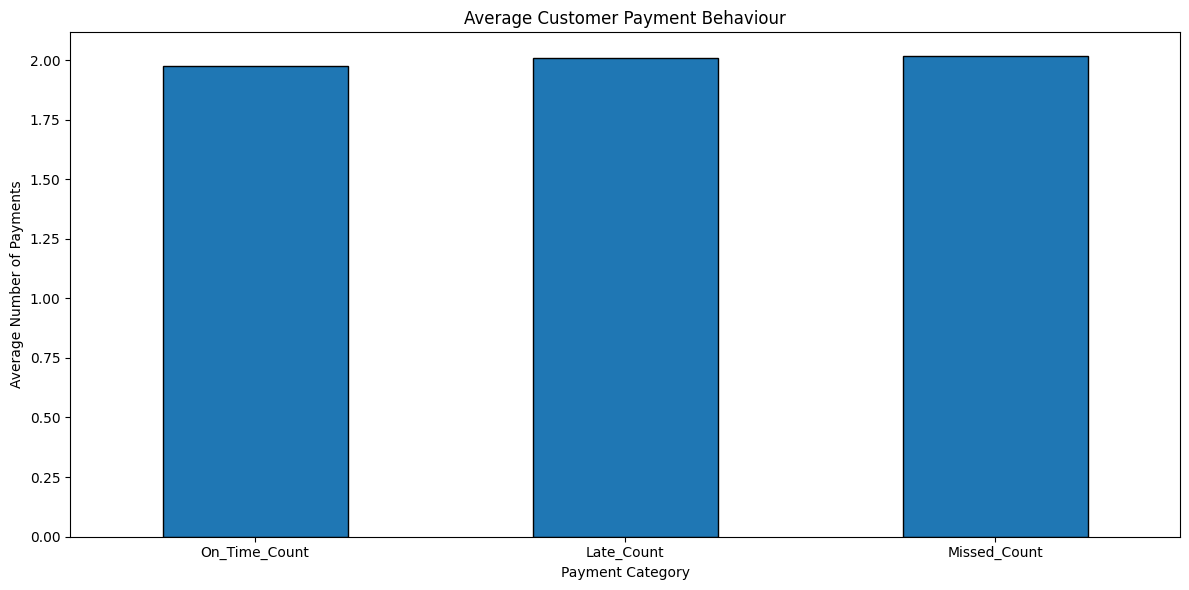

In [17]:
plt.figure(figsize=(12, 6))

data[
    ["On_Time_Count", "Late_Count", "Missed_Count"]
].mean().plot(kind="bar", edgecolor="black")

plt.title("Average Customer Payment Behaviour")
plt.ylabel("Average Number of Payments")
plt.xlabel("Payment Category")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [18]:
payment_analysis = data.groupby(
    "Delinquent_Account"
)[engineered_features].mean().T

payment_analysis.columns = [
    "Non_Delinquent",
    "Delinquent"
]

payment_analysis

,Non_Delinquent,Delinquent
On_Time_Count,1.961905,2.037500
Late_Count,2.021429,1.950000
Missed_Count,2.016667,2.012500
Payment_Records_Available,6.000000,6.000000
Payment_Issue_Count,4.038095,3.962500
Payment_Issue_Rate,0.673016,0.660417
Missed_Payment_Rate,0.336111,0.335417
On_Time_Rate,0.326984,0.339583
Average_Payment_Status,1.009127,0.995833


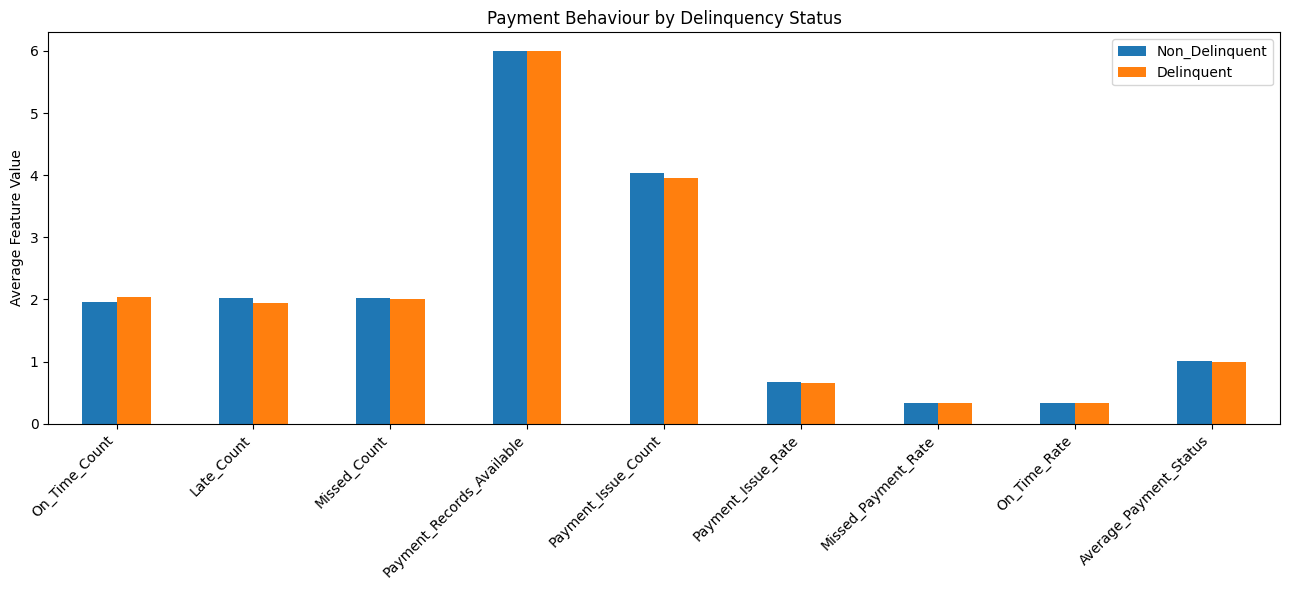

In [19]:
payment_analysis.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Payment Behaviour by Delinquency Status")
plt.ylabel("Average Feature Value")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [20]:
selected_features = [
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure",
    "On_Time_Count",
    "Late_Count",
    "Missed_Count",
    "Payment_Issue_Count",
    "Payment_Issue_Rate",
    "Missed_Payment_Rate",
    "On_Time_Rate",
    "Average_Payment_Status"
]

X = data[selected_features].copy()
y = data["Delinquent_Account"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (500, 15)
Target shape: (500,)


In [21]:
print("Target distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print(
    y.value_counts(normalize=True).mul(100).round(2)
)

Target distribution:
Delinquent_Account
0    420
1     80
Name: count, dtype: int64

Target percentages:
Delinquent_Account
0    84.0
1    16.0
Name: proportion, dtype: float64


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (400, 15)
Testing features: (100, 15)
Training target: (400,)
Testing target: (100,)


In [23]:
print("Training distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training distribution:
Delinquent_Account
0    0.84
1    0.16
Name: proportion, dtype: float64

Testing distribution:
Delinquent_Account
0    0.84
1    0.16
Name: proportion, dtype: float64


In [24]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created!")

Numerical preprocessing pipeline created!


In [25]:
X_train_processed = numeric_pipeline.fit_transform(X_train)
X_test_processed = numeric_pipeline.transform(X_test)
print("Training data processed:", X_train_processed.shape)
print("Testing data processed:", X_test_processed.shape)

Training data processed: (400, 15)
Testing data processed: (100, 15)


In [26]:
print(
    "Missing values in processed training data:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in processed testing data:",
    np.isnan(X_test_processed).sum()
)

Missing values in processed training data: 0
Missing values in processed testing data: 0


In [27]:
print(
    "Training feature means:",
    np.round(X_train_processed.mean(axis=0), 3)
)

print(
    "\nTraining feature standard deviations:",
    np.round(X_train_processed.std(axis=0), 3)
)

Training feature means: [-0.  0.  0.  0. -0.  0.  0. -0. -0.  0.  0. -0. -0. -0. -0.]

Training feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [28]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Overlapping indices:",
    len(set(X_train.index).intersection(set(X_test.index)))
)

Training records: 400
Testing records: 100
Overlapping indices: 0


In [30]:
import os
os.makedirs("../data/processed", exist_ok=True)
data.to_csv(
    "../data/processed/creditguard_engineered.csv",
    index=False
)
print("Engineered dataset saved successfully!")

Engineered dataset saved successfully!


In [31]:
feature_summary = pd.DataFrame({
    "Feature": selected_features,
    "Data_Type": X[selected_features].dtypes.astype(str).values
})

feature_summary.to_csv(
    "../data/processed/selected_features.csv",
    index=False
)

print("Feature list saved successfully!")

Feature list saved successfully!
